Clase 011 · `011_matplotlib2` · Con el mes que guardó la libreta anterior: `DataFrame.plot`
con `subplots=True` para ver todas las variables de un vistazo, y `resample` para pasar de
registros cada diez minutos a promedios por hora, por día y por año. Es la operación que
usarás en la libreta siguiente para construir el año promedio.

::: {.callout-important title="Datos"}
`esolmet_1mes_3marzo.parquet` lo produce la libreta `001_EDA` en
`clases/011_matplotlib2/data/002_intermediate/`; córrela primero.
:::

## Librerías

`pandas` y `matplotlib`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Todas las variables de un vistazo con `plot(subplots=True)`

`pandas` envuelve a matplotlib: `esolmet.plot(subplots=True)` crea un panel por columna
con el índice de fechas en el eje horizontal. El `;` al final evita que Jupyter imprima la
lista de `Axes`. Es la figura más rápida para detectar problemas: `p_atm` tiene un hueco
que la línea cruza en diagonal, `rain_acc` es casi todo ceros con lluvias puntuales, `wd`
está vacía casi todo el mes y el índice salta del 24 al 26 de marzo.

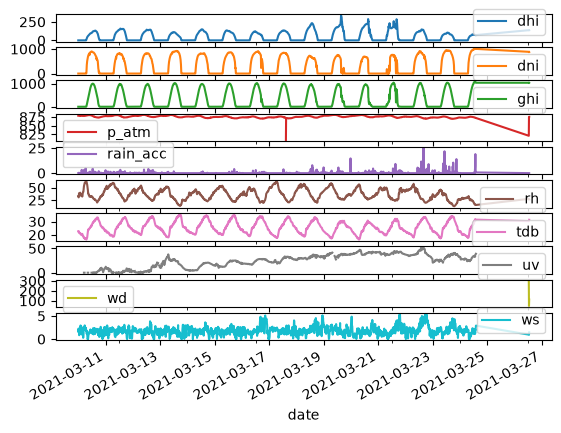

In [3]:
#| label: fig-ops-subplots-pandas
#| fig-cap: "Las diez variables de un mes de ESOLMET con `DataFrame.plot(subplots=True)`, un panel por columna. Se ven el hueco en la presión atmosférica, la dirección de viento casi vacía y el salto de fechas al final."
#| fig-alt: "Diez paneles apilados, uno por variable, con leyenda a la derecha; las irradiancias forman campanas diarias, la presión tiene una caída vertical, la dirección de viento sólo tiene un trazo al final."
f = "../data/002_intermediate/esolmet_1mes_3marzo.parquet"
esolmet = pd.read_parquet(f)
esolmet.plot(subplots=True);

## Cambiar de frecuencia con `resample`

`resample("1h").mean()` agrupa los registros de cada hora y los promedia; `resample("1D")`
hace lo mismo por día. Dibujamos las tres sobre el mismo `Axes`: la serie original en azul,
el promedio horario en naranja (casi encima, porque suaviza poco) y el promedio diario como
puntos verdes (`"go"`: color `g`, marcador `o`). Cada punto diario se dibuja a la
medianoche, que es el borde izquierdo de su intervalo.

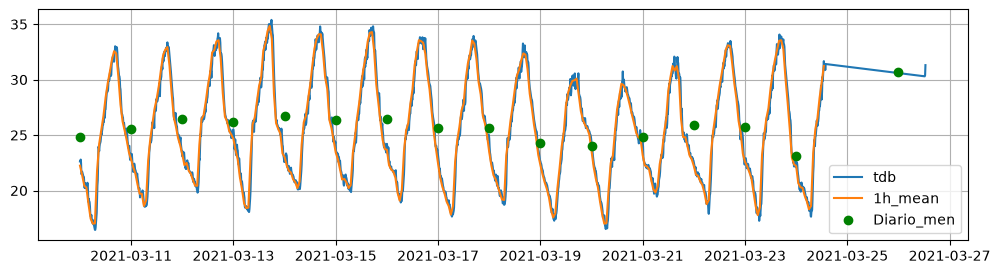

In [15]:
#| label: fig-ops-resample
#| fig-cap: "Temperatura cada diez minutos (azul), promedio horario (naranja) y promedio diario (puntos verdes) del 10 al 26 de marzo de 2021. El promedio diario borra el ciclo día-noche y deja un valor cerca de 25 °C."
#| fig-alt: "Serie azul y naranja casi superpuestas que oscilan entre 17 y 35 grados cada día, con un punto verde por día alrededor de 25 grados; al final un tramo recto donde faltan datos."
fig, ax = plt.subplots(figsize=(12,3))

ax.plot(esolmet.tdb,label="tdb")
ax.plot(esolmet.tdb.resample("1h").mean(),label="1h_mean")
ax.plot(esolmet.tdb.resample("1D").mean(),"go",label="Diario_men")

ax.legend()
ax.grid()

## La serie original

Registros cada diez minutos, 2103 en total, y el salto del 24 al 26 de marzo que ya se veía
en la figura.

In [16]:
esolmet.tdb

date
2021-03-10 00:00:00    22.62
2021-03-10 00:10:00    22.61
2021-03-10 00:20:00    22.79
2021-03-10 00:30:00    22.48
2021-03-10 00:40:00    21.48
                       ...  
2021-03-24 13:40:00    30.87
2021-03-24 13:50:00    31.41
2021-03-26 12:20:00    30.30
2021-03-26 12:30:00    30.39
2021-03-26 12:40:00    31.31
Name: tdb, Length: 2103, dtype: float64

## Promedio anual con `"YE"`

`"YE"` significa *year end*: un valor por año, fechado el 31 de diciembre. Como sólo hay un
mes de 2021 la respuesta es un número, 25.5 °C. En versiones de `pandas` anteriores a la
2.2 el alias era `"Y"`.

In [20]:
esolmet.tdb.resample("YE").mean()

date
2021-12-31    25.521165
Freq: YE-DEC, Name: tdb, dtype: float64